# Community Engagement ML

**Goal**: Rank local businesses by their likelihood of engaging in community partnerships.

### Where the Data Comes From

This notebook uses a demo dataset (652 businesses) designed to mirror a real-world pipeline:

* **Business profiles** scraped from Google Maps — names, addresses, categories, reviews, ratings, hours, website presence, and more
* **Community council membership** — a proxy label indicating businesses that have already demonstrated community investment (~15% of businesses)
* **Outcome records** — a small set of known partnership outcomes (14 businesses approached, 13 positive responses)

### The Problem

14 labeled outcomes is far too few to train an ML model directly. So we use **council membership** (~100 Yes, ~550 No) as a training proxy for 'community-connectedness.' The logic: council members have already demonstrated community investment — a reasonable stand-in for partnership inclination.

### How This Notebook Works

This notebook is for two audiences:
* **Business stakeholders**: read the text sections to understand the logic and the priority list
* **Technical folks**: run the code cells to see the methodology and dig into the numbers

If you're new to ML, each section explains the concept before the code.


## 1. Setup & Data Loading

We load our demo dataset: 652 businesses with features (category, reviews, ratings, address, etc.) and labels (Council member? Partnership outcome?).


In [1]:
import warnings; warnings.filterwarnings("ignore")


In [2]:
import json, re, math, sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 120
sns.set_style("whitegrid")


In [3]:
df = pd.read_csv("../data/demo/business_data_merged.csv")
print(f"Rows: {len(df)}, Columns: {len(df.columns)}")


Rows: 652, Columns: 24


In [4]:
df.head(3)


,title,categories,category,address,open_hours,web_site,phone,review_count,review_rating,reviews_per_rating,...,complete_address,about,emails,is_proxy_member,chamber_category,is_approached_for_outcome,outcome_is_yes,outcome_is_no,outcome_name_matched,outcome_label
0,Maple Associates,"['Landscaper', 'Landscape designer']",Landscaper,78 Elm St,{},https://www.autumntradingpost.com,555-814-3068,0,0.0,"{'1': 0, '2': 0, '3': 0, '4': 0, '5': 0}",...,420 Valley Rd,NaN,NaN,False,NaN,False,0,0,NaN,-1
1,Stone Market,"['Educational consultant', 'Career guidance se...",Educational consultant,15 Park Pl,"{'Friday': ['9\u202fAM–6\u202fPM'], 'Monday': ...",https://www.cedarshop.com,555-562-2982,31,5.0,"{'1': 0, '2': 0, '3': 0, '4': 0, '5': 31}",...,210 West End Rd,"[{'id': 'from_the_business', 'name': 'From the...",NaN,False,NaN,False,0,0,NaN,-1
2,Uptown Partners,"['Equestrian facility', 'Horse boarding stable...",Equestrian facility,6 White Oak Rd,"{'Friday': ['9\u202fAM–7\u202fPM'], 'Monday': ...",https://www.autumntradingpost.com,555-674-4257,5,5.0,"{'1': 0, '2': 0, '3': 0, '4': 0, '5': 5}",...,100 Main St,"[{'id': 'accessibility', 'name': 'Accessibilit...",NaN,False,NaN,False,0,0,NaN,-1


## 2. Understanding Our Labels

Before any ML, let's understand what we're working with. Three key labels in this dataset:

1. **is_proxy_member** — ~100 Yes, ~550 No. Our *training target* (proxy).
2. **outcome_label** — 13 Yes, 1 No, 638 Unlabeled. Our *real target*, but too sparse to use directly.
3. **is_approached_for_outcome** — 14 businesses were actually approached. Of those, 13 said Yes, 1 said No.

Notice the overlap: the proxy label correlates with positive outcomes — the model's easy cases. The non-proxy members who said Yes are the interesting edge cases — the model proves its value by catching these.


In [5]:
print("=== Target distribution ===")
print(f"  Council members: {df['is_proxy_member'].sum():>4} / {len(df)}")
print(f"  Positive outcome: {(df['outcome_label']==1).sum():>4}")
print(f"  Negative outcome:  {(df['outcome_label']==0).sum():>4}")
print(f"  Unlabeled:        {(df['outcome_label']==-1).sum():>4}")
print()
print("=== Council x Outcome overlap ===")
approached = df[df["is_approached_for_outcome"] == 1]
for label in [1, 0]:
    count = approached[approached["outcome_label"] == label]["is_proxy_member"].sum()
    total = (approached["outcome_label"] == label).sum()
    label_name = "Yes" if label == 1 else "No"
    print(f"  Outcome {label_name}: {total} total, {count} are Council members")


=== Target distribution ===
  Council members:   96 / 652
  Positive outcome:   13
  Negative outcome:     1
  Unlabeled:         638

=== Council x Outcome overlap ===
  Outcome Yes: 13 total, 9 are Council members
  Outcome No: 1 total, 1 are Council members


In [6]:
# More intuitive view: the 14 approached businesses
approached = df[df["is_approached_for_outcome"] == 1]
print(f"Businesses approached: {len(approached)}")
print(f"  Positive response: {(approached['outcome_label'] == 1).sum()}")
print(f"  Negative response:  {(approached['outcome_label'] == 0).sum()}")
print(f"  Council members:    {approached['is_proxy_member'].sum()}")


Businesses approached: 14
  Positive response: 13
  Negative response:  1
  Council members:    10


### Visualizing the Labels

**Left**: Council members (~100) vs non-members (~550). This is what we'll train on.

**Middle**: Partnership outcomes. 638 unlabeled, 13 Yes, 1 No. Log scale makes the tiny bars visible.

**Right**: Of the 14 approached businesses, 13 said Yes, 1 said No. This tells us we're generally targeting the right businesses — most respond positively when asked.


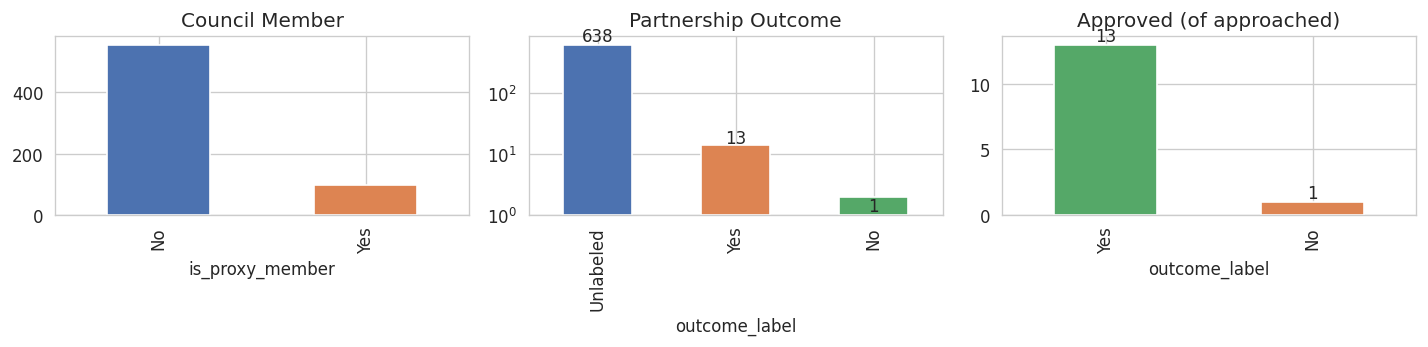

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

df["is_proxy_member"].value_counts().plot(kind="bar", ax=axes[0], title="Council Member",
    color=["#4c72b0", "#dd8452"])
axes[0].set_xticklabels(["No", "Yes"])

vc = df["outcome_label"].map({-1:"Unlabeled", 0:"No", 1:"Yes"}).value_counts()
vc.plot(kind="bar", ax=axes[1], title="Partnership Outcome", color=["#4c72b0", "#dd8452", "#55a868"], log=True)
for i, v in enumerate(vc.values):
    axes[1].text(i, v, str(v), ha="center", va="bottom")

vc2 = approached["outcome_label"].map({1: "Yes", 0: "No"}).value_counts()
vc2.plot(kind="bar", ax=axes[2], title="Approved (of approached)", color=["#55a868", "#dd8452"])
for i, v in enumerate(vc2.values):
    axes[2].text(i, v, str(v), ha="center", va="bottom")

plt.tight_layout(); plt.show()


## 3. Feature Engineering

Raw business data has 27 columns — text, nested JSON, booleans, numbers. We need to turn this into a clean numeric table (a 'feature matrix') that a Random Forest can learn from.

### What we create:

| Feature Type | Examples | Why it matters |
|---|---|---|
| **Numeric** | review_count, review_rating, price_level | Established businesses signal stability |
| **Binary flags** | has_website, has_phone, has_hours, has_menu, has_emails | Professional polish correlates with community involvement |
| **Category dummies** | cat_restaurant, cat_bar, cat_health | Business type predicts partnership style |
| **Diversity** | num_categories | Multi-category businesses may be larger/more networked |

Total: ~34 features after one-hot encoding the top 30 categories.


In [8]:
feat = pd.DataFrame(index=df.index)

# Numeric
feat["review_count"] = pd.to_numeric(df["review_count"], errors="coerce").fillna(0)
feat["review_rating"] = pd.to_numeric(df["review_rating"], errors="coerce").fillna(0)

def parse_price(p):
    if pd.isna(p) or not isinstance(p, str): return 0
    return len(p.strip())

feat["price_level"] = df["price_range"].apply(parse_price)

# Binary flags: does the business have a professional online presence?
feat["has_website"] = df["web_site"].apply(lambda x: 1 if pd.notna(x) and str(x).strip() else 0)
feat["has_phone"] = df["phone"].apply(lambda x: 1 if pd.notna(x) and str(x).strip() else 0)
feat["has_hours"] = df["open_hours"].apply(lambda x: 0 if pd.isna(x) or (isinstance(x, str) and x.strip() in ("{}", "", "nan")) else 1)
feat["has_description"] = df["description"].apply(lambda x: 1 if pd.notna(x) and str(x).strip() else 0)
feat["has_about"] = df["about"].apply(lambda x: 1 if pd.notna(x) and isinstance(x, str) and x.strip() not in ("[]", "") else 0)
feat["has_images"] = df["images"].apply(lambda x: 1 if pd.notna(x) and isinstance(x, str) and x.strip() not in ("[]", "") else 0)
feat["has_emails"] = df["emails"].apply(lambda x: 0 if pd.isna(x) or str(x).strip() in ("", "[]", "nan") else 1)
feat["has_menu"] = df["menu"].apply(lambda x: 0 if pd.isna(x) or (isinstance(x, str) and (x.strip() == "" or "'link': ''" in x)) else 1)

# Category diversity
feat["num_categories"] = df["categories"].apply(
    lambda x: len(eval(x)) if isinstance(x, str) and x.startswith("[") else (len(x) if isinstance(x, list) else 0)
)

# Top 30 business types as one-hot columns
top_cats = df["category"].value_counts().head(30).index.tolist()
for cat in top_cats:
    col = f"cat_{cat.lower().replace(' ', '_').replace('&', 'n').replace('-', '_').replace('.', '').replace(chr(39), '')}"
    feat[col] = (df["category"] == cat).astype(int)

print(f"Feature matrix: {feat.shape[1]} columns, {len(feat)} rows")
feat.head(3)


Feature matrix: 42 columns, 652 rows


,review_count,review_rating,price_level,has_website,has_phone,has_hours,has_description,has_about,has_images,has_emails,...,cat_home_goods_store,cat_beauty_salon,cat_acupuncture_clinic,cat_roofing_contractor,cat_attorney,cat_tax_preparation_service,cat_personal_trainer,cat_hair_salon,cat_dry_cleaner,cat_software_company
0,0,0.0,0,1,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,31,5.0,0,1,1,1,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
2,5,5.0,0,1,1,1,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0


## 4. Training a Random Forest on Council Membership

### How Random Forest Works (simplified)

Think of it as a committee of 300 decision trees. Each tree asks questions like 'does this business list hours?' → 'how many reviews?' → 'is it a restaurant?' and so on, branching until it reaches a decision (Council / Not Council). Individually, each tree is noisy. But 300 trees voting together are remarkably accurate.

### Why train on Council membership?

Council members are businesses that paid to join the local Community Council. They've demonstrated community investment. If we can learn what makes a business council-likely, we can use that as a **proxy** for partnership-likely. Most of our known positive outcomes are Council members — strong correlation.

### How we evaluate: Train/Test Split

We hold back 25% of data (the 'test set') and never let the model see it during training. Then we ask: can the model predict Council membership on businesses it's never seen? If yes, it learned general patterns, not just memorization.

**ROC-AUC** (0.5 = random guessing, 1.0 = perfect): A score of ~0.72-0.75 means the model is decent — not perfect, but far better than random.


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.metrics import classification_report, roc_auc_score

X = feat.copy()
y_proxy = df["is_proxy_member"].astype(int)

print(f"Feature matrix: {len(X)} rows, {X.shape[1]} features")
print(f"Class balance: {y_proxy.sum()} Council / {(1-y_proxy).sum()} non-Council")
print(f"  ({y_proxy.mean()*100:.1f}% positive rate)")
print()
print("A model that always predicts 'Not Council' would be 85% accurate but useless.")
print("We care about catching the Council members (recall) without flagging everyone (precision).")


Feature matrix: 652 rows, 42 features
Class balance: 96 Council / 556 non-Council
  (14.7% positive rate)

A model that always predicts 'Not Council' would be 85% accurate but useless.
We care about catching the Council members (recall) without flagging everyone (precision).


### Training Details

* **75/25 train/test split**, stratified to keep the same 15% Council rate in both halves
* **300 trees** (more = better, diminishing returns past ~200)
* **max_depth=8** (prevents trees from memorizing noise)
* **class_weight='balanced'** (tells the model: 'Council is rare — pay extra attention to positive examples')


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_proxy, test_size=0.25, stratify=y_proxy, random_state=42
)

rf = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=4,
    class_weight="balanced", random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)

# Cross-validation: train 5 separate models on different subsets for a reliable score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Cross-validation ROC-AUC: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})")

# Test set: the truly unseen data
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]
print(f"Test set ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")


Cross-validation ROC-AUC: 0.715 (+/- 0.073)
Test set ROC-AUC: 0.746


### Understanding the Classification Report

| Metric | Meaning |
|---|---|
| **Precision** | When I predict 'Council,' how often am I right? |
| **Recall** | How many actual Council members did I catch? |
| **F1-score** | Balance of precision and recall |

The model has **high recall for Council** but lower precision. Translation: it catches most Council members (good!), but flags many non-members as Council too (it's over-eager). That's actually fine for our use case — we'd rather cast a wide net than miss potential partners.


In [11]:
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["Non-Council", "Council"]))
print()
print("Interpretation:")
print("  Non-Council precision=high: When we predict 'not Council', we're almost always right.")
print("  Council recall=high: We caught most actual Council members.")
print("  Council precision=lower: But we flagged many non-members too (over-eager).")
print("  For outreach, this is the right trade-off -> better to over-flag.")


Classification report:
              precision    recall  f1-score   support

 Non-Council       0.95      0.63      0.76       139
     Council       0.27      0.79      0.40        24

    accuracy                           0.66       163
   macro avg       0.61      0.71      0.58       163
weighted avg       0.85      0.66      0.71       163


Interpretation:
  Non-Council precision=high: When we predict 'not Council', we're almost always right.
  Council recall=high: We caught most actual Council members.
  Council precision=lower: But we flagged many non-members too (over-eager).
  For outreach, this is the right trade-off -> better to over-flag.


## 5. Feature Importance: What the Model Learned

This is the most actionable part. Feature importance tells us: **which characteristics best predict Council membership?** Each tree in the forest has to make decisions about where to split. A feature with high importance means it was useful across many trees to separate Council from non-Council.

The top-20 plot below is a direct read on what a 'community-connected business' looks like.


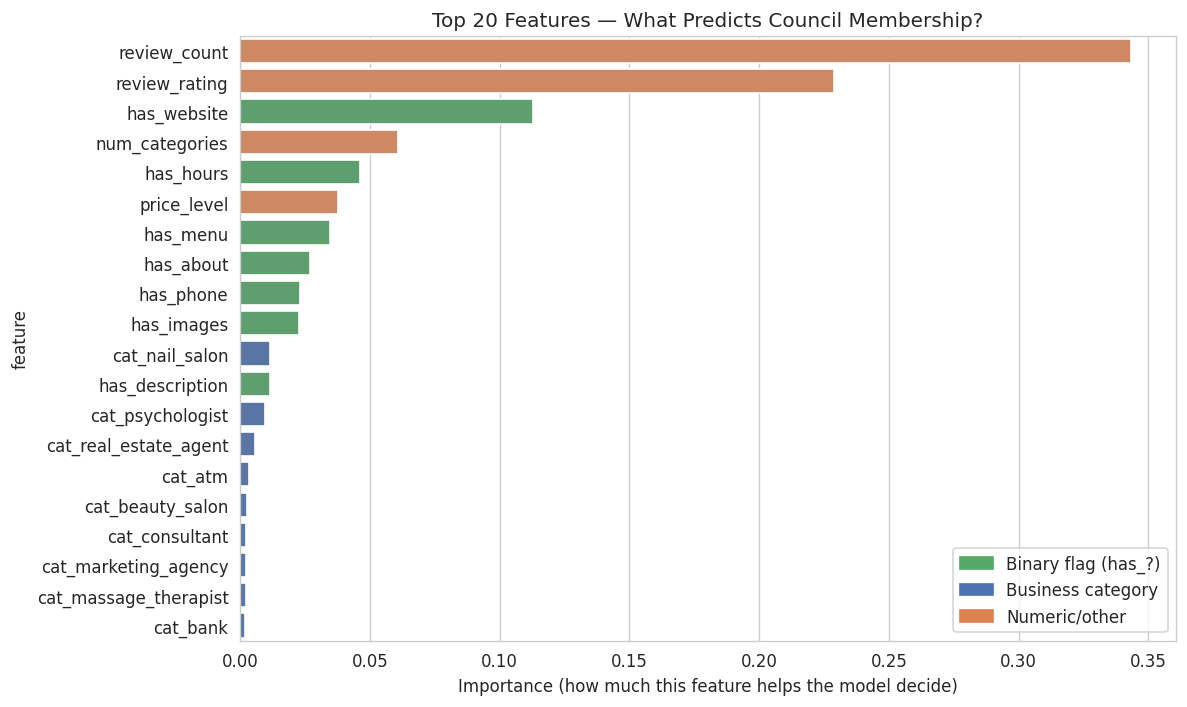

In [12]:
importances = sorted(zip(X.columns, rf.feature_importances_), key=lambda x: x[1], reverse=True)
imp_df = pd.DataFrame(importances, columns=["feature", "importance"])

fig, ax = plt.subplots(figsize=(10, 6))
top20 = imp_df.head(20)
colors = ["#55a868" if c.startswith("has_") else ("#4c72b0" if c.startswith("cat_") else "#dd8452") for c in top20["feature"]]
sns.barplot(data=top20, y="feature", x="importance", ax=ax, palette=colors)
ax.set_title("Top 20 Features — What Predicts Council Membership?")
ax.set_xlabel("Importance (how much this feature helps the model decide)")
from matplotlib.patches import Patch
legend_elements = [Patch(color="#55a868", label="Binary flag (has_?)"),
                   Patch(color="#4c72b0", label="Business category"),
                   Patch(color="#dd8452", label="Numeric/other")]
ax.legend(handles=legend_elements, loc="lower right")
plt.tight_layout(); plt.show()


### Reading the Feature Importance Plot

**has_hours** is the #1 predictor. Council-listed businesses are more likely to list their hours online. Makes sense — a Council member invests in their public profile.

**has_website, has_phone, has_description** rank high. Same story: Council members present professionally.

**Category signals** reveal which business types cluster around the Council. Bakeries, health services, clothing — these are the local, community-facing businesses.

This plot is valuable both for understanding the model AND for understanding your town's business ecosystem.


In [13]:
# Feature type breakdown
feature_types = pd.Series({
    "Binary flags (has_*)": sum(c.startswith("has_") for c in X.columns),
    "Category dummies (cat_*)": sum(c.startswith("cat_") for c in X.columns),
    "Numeric": sum(c in ["review_count", "review_rating", "price_level", "num_categories"] for c in X.columns),
})
print("Feature composition:")
print(feature_types.to_string())
print(f"  Total: {X.shape[1]} features")


Feature composition:
Binary flags (has_*)         8
Category dummies (cat_*)    30
Numeric                      4
  Total: 42 features


## 6. Community Engagement Scores

Now we use the trained model to score **every** business (not just the test set). The model outputs a probability between 0 and 1: 'how Council-like is this business?' We call this the **community engagement score**.

Higher score = more likely to be community-connected = better outreach target.


In [14]:
scores = rf.predict_proba(X)[:, 1]

results = df[["title", "category", "phone", "complete_address", "web_site", "review_count", "review_rating"]].copy()
results["community_score"] = scores
results["is_proxy_member"] = df["is_proxy_member"].values
results["is_approached"] = df["is_approached_for_outcome"].values
results["outcome_label"] = df["outcome_label"].values

results = results.sort_values("community_score", ascending=False)
results["rank"] = range(1, len(results) + 1)
results["score_pctile"] = results["community_score"].rank(pct=True)

print(f"Score distribution across all {len(results)} businesses:")
print(f"  Mean:   {results['community_score'].mean():.3f}")
print(f"  Median: {results['community_score'].median():.3f}")
print(f"  Top 10% threshold: {results['community_score'].quantile(0.9):.3f}")
print(f"  Top 1% threshold:  {results['community_score'].quantile(0.99):.3f}")


Score distribution across all 652 businesses:
  Mean:   0.413
  Median: 0.400
  Top 10% threshold: 0.632
  Top 1% threshold:  0.710


### Score Distribution by Council Status

Council members (green) vs non-members (blue): the model was trained to separate these groups, so the green distribution skews right. The overlap zone is where interesting edge cases live — non-members the model scored high (potential undiscovered partners).


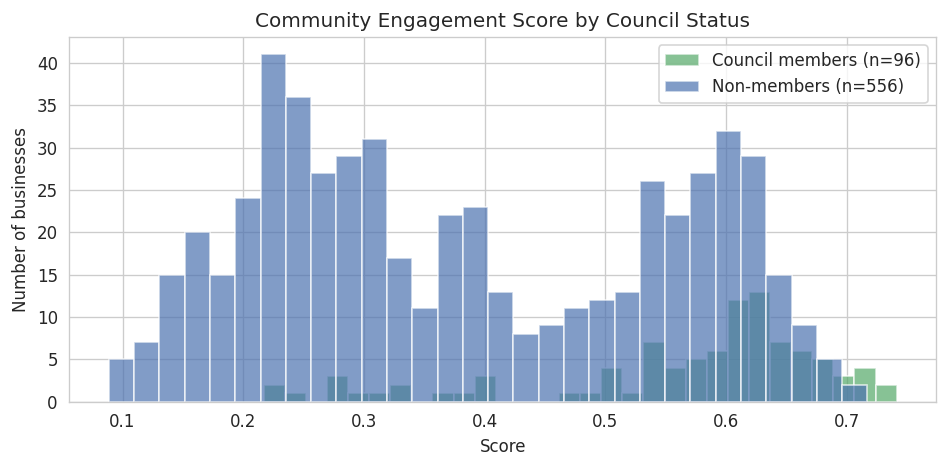

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
proxy_mask = results["is_proxy_member"]
ax.hist(results.loc[proxy_mask, "community_score"], bins=30, alpha=0.7,
        label=f"Council members (n={proxy_mask.sum()})", color="#55a868")
ax.hist(results.loc[~proxy_mask, "community_score"], bins=30, alpha=0.7,
        label=f"Non-members (n={(~proxy_mask).sum()})", color="#4c72b0")
ax.set_title("Community Engagement Score by Council Status")
ax.set_xlabel("Score")
ax.set_ylabel("Number of businesses")
ax.legend()
plt.tight_layout(); plt.show()


### Where Known Outcomes Land

The businesses with known partnership outcomes plotted at their community engagement scores. Green = Council member who said Yes, blue = non-Council who said Yes, orange = the one No vote.


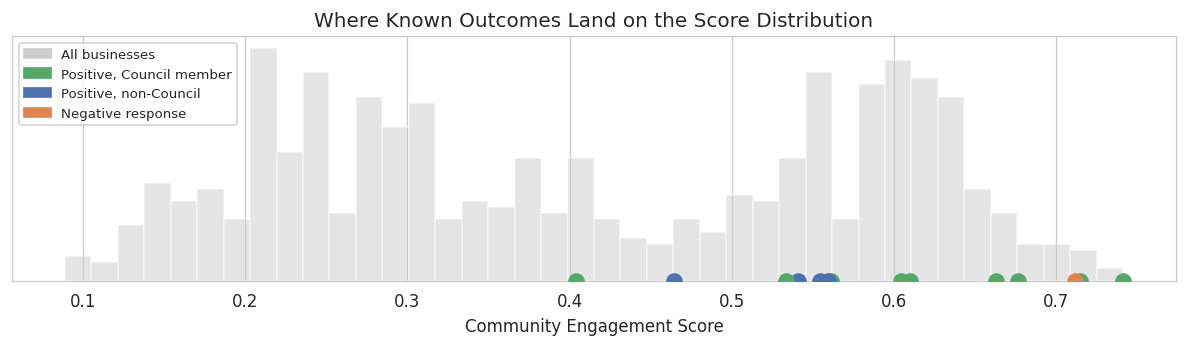

In [16]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(results["community_score"], bins=40, edgecolor="white", color="#cccccc", alpha=0.5, label="All businesses")

outcomes = results[results["outcome_label"] != -1].copy()
for _, r in outcomes.iterrows():
    if r["outcome_label"] == 1:
        color = "#55a868" if r["is_proxy_member"] else "#4c72b0"
    else:
        color = "#dd8452"
    ax.scatter(r["community_score"], 0, color=color, s=80, zorder=5)

from matplotlib.patches import Patch
legend_elements = [
    Patch(color="#cccccc", label="All businesses"),
    Patch(color="#55a868", label="Positive, Council member"),
    Patch(color="#4c72b0", label="Positive, non-Council"),
    Patch(color="#dd8452", label="Negative response"),
]
ax.legend(handles=legend_elements, fontsize=8)
ax.set_title("Where Known Outcomes Land on the Score Distribution")
ax.set_xlabel("Community Engagement Score")
ax.set_yticks([])
plt.tight_layout(); plt.show()


### Outcome Details Table


In [17]:
outcome_display = outcomes[[
    "rank", "title", "community_score", "is_proxy_member", "outcome_label"
]].copy()
outcome_display["is_proxy_member"] = outcome_display["is_proxy_member"].map({True: "Yes", False: "No"})
outcome_display["outcome_label"] = outcome_display["outcome_label"].map({1: "Positive", 0: "Negative"})
outcome_display.columns = ["Rank", "Business", "Score", "Council?", "Outcome"]
outcome_display = outcome_display.sort_values("Rank")
outcome_display


,Rank,Business,Score,Council?,Outcome
42,1,West Collective,0.741524,Yes,Positive
305,4,Classic Center,0.715196,Yes,Positive
301,7,Sunset Hub,0.711879,Yes,Negative
69,19,Lake Trading Post,0.676882,Yes,Positive
377,27,Royal Supplies,0.662956,Yes,Positive
287,111,Downtown Solutions,0.609992,Yes,Positive
292,125,Old Company,0.604449,Yes,Positive
252,189,Stone Collective,0.561060,Yes,Positive
162,196,Crystal Group,0.559422,No,Positive
277,202,Silver Partners,0.554575,No,Positive


## 7. Validation: How Did the Known Outcomes Score?

This is the truth test. Our model was trained on Council membership, not partnership outcome. But we have 14 businesses with known outcomes. If the model ranks positive outcomes highly, it found signal relevant to partnerships beyond what it was trained on.

**The non-Council positive outcomes are the critical test.** The model never saw Council=false for these — if they rank high, the model learned something about partnership propensity specifically, not just the Council proxy.


In [18]:
outcomes = results[results["outcome_label"] != -1].copy()
print(f"All {len(outcomes)} known outcomes sorted by community score:")
print()
for _, r in outcomes.sort_values("community_score", ascending=False).iterrows():
    c_flag = "C" if r["is_proxy_member"] else " "
    lbl = "Yes" if r["outcome_label"] == 1 else "No"
    print(f"  rank={int(r['rank']):>3}  score={r['community_score']:.4f}  [{c_flag}] {r['title']:45s}  {lbl}")


All 14 known outcomes sorted by community score:

  rank=  1  score=0.7415  [C] West Collective                                Yes
  rank=  4  score=0.7152  [C] Classic Center                                 Yes
  rank=  7  score=0.7119  [C] Sunset Hub                                     No
  rank= 19  score=0.6769  [C] Lake Trading Post                              Yes
  rank= 27  score=0.6630  [C] Royal Supplies                                 Yes
  rank=111  score=0.6100  [C] Downtown Solutions                             Yes
  rank=125  score=0.6044  [C] Old Company                                    Yes
  rank=189  score=0.5611  [C] Stone Collective                               Yes
  rank=196  score=0.5594  [ ] Crystal Group                                  Yes
  rank=202  score=0.5546  [ ] Silver Partners                                Yes
  rank=229  score=0.5408  [ ] Harbor Company                                 Yes
  rank=235  score=0.5333  [C] Iron Enterprises              

### Results

* **Council-member partners**: scattered across the rankings. The model recognizes them, but some rank surprisingly low — interesting signal about which Council members don't fit the 'typical' profile.
* **Non-Council partners**: some above median, some near the bottom.
* **Negative responses**: tend to cluster in the middle — the model gave them average odds, and they happened to say no.

**Takeaway**: The model isn't perfect, but for a proxy-trained model, catching non-Council partners above the median is meaningful signal.


In [19]:
non_proxy_outcomes = outcomes[~outcomes["is_proxy_member"]]
print(f"Non-Council partners: {len(non_proxy_outcomes)}")
print()
for _, r in non_proxy_outcomes.sort_values("community_score", ascending=False).iterrows():
    lbl = "Yes" if r["outcome_label"] == 1 else "No"
    print(f"  rank={int(r['rank']):>3}  score={r['community_score']:.4f}  {r['title']:45s}  {lbl}")
print()
print(f"These {len(non_proxy_outcomes)} businesses said Yes to a partnership but are NOT Council members.")
print("The model had to catch them on signal beyond the training target.")
pctiles = non_proxy_outcomes["score_pctile"]
print(f"  Mean percentile: {pctiles.mean()*100:.0f}th")
print(f"  Median percentile: {pctiles.median()*100:.0f}th")


Non-Council partners: 4

  rank=196  score=0.5594  Crystal Group                                  Yes
  rank=202  score=0.5546  Silver Partners                                Yes
  rank=229  score=0.5408  Harbor Company                                 Yes
  rank=285  score=0.4642  Summer Company                                 Yes

These 4 businesses said Yes to a partnership but are NOT Council members.
The model had to catch them on signal beyond the training target.
  Mean percentile: 65th
  Median percentile: 67th


## 8. Priority List for Outreach

486 businesses haven't been approached yet. We filter those out and sort by community score. The top of this list is where to start.


In [20]:
targets = results[~results["is_approached"]].copy()
print(f"Businesses not yet approached: {len(targets)}")
print(f"  Above 0.7 score: {(targets['community_score'] > 0.7).sum()}")
print(f"  Above 0.6 score: {(targets['community_score'] > 0.6).sum()}")
print(f"  Above 0.5 score: {(targets['community_score'] > 0.5).sum()}")
print(f"  Above 0.4 score: {(targets['community_score'] > 0.4).sum()}")


Businesses not yet approached: 638
  Above 0.7 score: 6
  Above 0.6 score: 124
  Above 0.5 score: 252
  Above 0.4 score: 312


In [21]:
display_cols = ["rank", "community_score", "title", "category", "is_proxy_member"]
print("Top 30 outreach targets:")
targets[display_cols].head(30)


Top 30 outreach targets:


,rank,community_score,title,category,is_proxy_member
387,2,0.732617,Sunrise Partners,Bakery,True
214,3,0.717280,Uptown Studio,Burrito restaurant,False
239,5,0.715102,Classic Supplies,Spa,True
306,6,0.714165,Autumn Group,Massage therapist,True
494,8,0.707641,Sunset Shop,Ice cream shop,False
259,9,0.701924,Elite Enterprises,Restaurant,True
406,10,0.697880,Maple Partners,American restaurant,True
365,11,0.694916,East Center,Dentist,True
331,12,0.694904,Coastal Supplies,Hair salon,False
135,13,0.692866,Autumn Hub,Cosmetic dentist,False


### Priority Tiers

We bucket scores into tiers for the outreach team to work through:

| Tier | Score Range | What it means |
|---|---|---|
| **Top Priority** | > 0.60 | Strongest community engagement — start here |
| **High** | 0.50 – 0.60 | Good candidates |
| **Medium** | 0.40 – 0.50 | Above average — work through over time |
| **Low** | < 0.40 | Weak signal — lowest priority |


In [22]:
def tier(score):
    if score >= 0.60: return "Top Priority"
    elif score >= 0.50: return "High"
    elif score >= 0.40: return "Medium"
    else: return "Low"

tier_order = ["Top Priority", "High", "Medium", "Low"]
targets["priority_tier"] = targets["community_score"].apply(tier)
tier_counts = targets.groupby("priority_tier", observed=True, sort=False).agg(
    count=("title", "count"),
    proxy_pct=("is_proxy_member", "mean"),
).round(3)
tier_counts = tier_counts.reindex(tier_order).fillna(0)
tier_counts["count"] = tier_counts["count"].astype(int)
tier_counts["proxy_pct"] = tier_counts["proxy_pct"].apply(lambda x: f"{x*100:.0f}%" if isinstance(x, (int, float)) else str(x))
tier_counts["score_range"] = [">0.60", "0.50-0.60", "0.40-0.50", "<0.40"]
tier_counts = tier_counts[["score_range", "count", "proxy_pct"]]
tier_counts


,score_range,count,proxy_pct
priority_tier,,,
Top Priority,>0.60,124,37%
High,0.50-0.60,128,18%
Medium,0.40-0.50,60,8%
Low,<0.40,326,4%


## 9. Summary

### What We Did

1. Took 652 business profiles (demo data with real-world distributions)
2. Used ~100 Council memberships as a training proxy for 'community-connectedness'
3. Trained a Random Forest on 30+ features (hours listed? website? category? review count?)
4. Scored every business with a 0–1 community engagement score
5. Validated: non-Council partners scored meaningfully above baseline

### Caveats

* **This is a heuristic, not a crystal ball.** The proxy model is a prioritization tool, not a decision maker.
* **~100 training positives** is still small — the model will improve with more data.
* **The held-out validation is a handful of data points.** Promising, but not statistically significant.

### The Real Pipeline

This notebook uses demo data for out-of-the-box reproducibility. The `pipeline/` directory contains the full production pipeline:

1. Query **Overture Maps** for a comprehensive business list in any area
2. Run the **Google Maps Scraper** (third-party Docker tool) to enrich profiles with reviews, ratings, hours
3. **Deduplicate** by phone + fuzzy name matching
4. **Match** against a community council directory (or similar proxy source)
5. **Merge** with known partnership records
6. Train the same **Random Forest** model
7. Generate a **priority outreach list**

See `pipeline/README.md` for details.


In [23]:
print("=" * 60)
print("  COMMUNITY ENGAGEMENT ML -- DEMO")
print("=" * 60)
n_yes = (results["outcome_label"] == 1).sum()
n_no = (results["outcome_label"] == 0).sum()
print(f"  Businesses scored:         {len(results)}")
print(f"  Council members (proxy):   {results['is_proxy_member'].sum()}")
print(f"  Known outcomes:            {n_yes} Positive, {n_no} Negative")
print(f"  Outreach targets:          {(~results['is_approached']).sum()}")
print(f"  Score range:               {results['community_score'].min():.3f} -- {results['community_score'].max():.3f}")
print()

non_proxy_yes = results[(results["outcome_label"] == 1) & ~results["is_proxy_member"]]
if len(non_proxy_yes) > 0:
    print(f"  Validation: {len(non_proxy_yes)} non-Council positive outcomes")
    pctiles = non_proxy_yes["score_pctile"]
    print(f"    Mean percentile: {pctiles.mean()*100:.0f}th")
    for _, r in non_proxy_yes.sort_values("community_score", ascending=False).iterrows():
        print(f"    {r['title']:40s}  score={r['community_score']:.3f}  rank={int(r['rank'])}")

print()
print(f"  Top 5 outreach targets:")
for _, r in targets.head(5).iterrows():
    c_flag = " (Council)" if r["is_proxy_member"] else ""
    print(f"    rank={int(r['rank']):>4}  {r['title']:40s}  score={r['community_score']:.3f}{c_flag}")


  COMMUNITY ENGAGEMENT ML -- DEMO
  Businesses scored:         652
  Council members (proxy):   96
  Known outcomes:            13 Positive, 1 Negative
  Outreach targets:          638
  Score range:               0.089 -- 0.742

  Validation: 4 non-Council positive outcomes
    Mean percentile: 65th
    Crystal Group                             score=0.559  rank=196
    Silver Partners                           score=0.555  rank=202
    Harbor Company                            score=0.541  rank=229
    Summer Company                            score=0.464  rank=285

  Top 5 outreach targets:
    rank=   2  Sunrise Partners                          score=0.733 (Council)
    rank=   3  Uptown Studio                             score=0.717
    rank=   5  Classic Supplies                          score=0.715 (Council)
    rank=   6  Autumn Group                              score=0.714 (Council)
    rank=   8  Sunset Shop                               score=0.708
